In [1]:
NAME = "Garvit Gopalani"

import torch, transformers
print("Name:        ", NAME)
print("torch:       ", torch.__version__)
print("transformers:", transformers.__version__)

Name:         Garvit Gopalani
torch:        2.14.1+cu130
transformers: 5.22.1


# CSE 256 PA2, Part 3: Dissecting a Pretrained LLM

Model: `EleutherAI/pythia-160m-deduped` (12 layers, 12 heads per layer, $d = 768$), loaded in float32 at the
checkpoints `step0`, `step512`, `step1000`, `step8000`, `step32000` and `step143000` (final).

`transformers` is only used to load the model and tokenizer and to run the forward pass.
The logit lens and the layer transplants are implemented by hand below.

## Questions and where they are answered

Each question below has the handout's question in a box, then the code and outputs, then a Markdown cell headed **Answer**.

| Question | Gradescope item | Points | Where |
|---|---|---|---|
| 3.1.1 Why checkpoints? | 3.1 | 2 | Answer 3.1.1 |
| 3.1.2 Data | 3.2 | 2 | Answer 3.1.2 |
| 3.2.1 Watch a prediction form | 4.1 | 13 | Grids (i) and (ii), accuracy curve (iii), Answer 3.2.1 |
| 3.2.2 Across training | 4.2 | 13 | Four-checkpoint plot, Answer 3.2.2 |
| 3.3 Transplanting layers across time | 5 | 20 | Heatmap, extra plots and experiment, Answer 3.3 |

## Setup

Run on a GPU runtime (Colab: *Runtime → Change runtime type → T4 GPU*). A CPU also works, just more slowly.
Upload `test_LM_obama.txt` to `/content` (Colab's working folder) before running; the data cell reads it from there.
The first run downloads six checkpoints of about 650 MB each (about 4 GB in total).

In [2]:
import os, gc, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import torch.nn.functional as F
from transformers import AutoTokenizer, GPTNeoXForCausalLM

T_START = time.time()
torch.manual_seed(0)
torch.set_grad_enabled(False)            # inference only, no gradients anywhere in this notebook

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, f"({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else "")

MODEL_NAME = "EleutherAI/pythia-160m-deduped"
FINAL = "step143000"
CTX = 2048                               # Pythia's context length

device: cuda (Tesla T4)


In [3]:
OBAMA_PATH = '/content/test_LM_obama.txt'
with open(OBAMA_PATH, encoding="utf-8") as f:
    obama_text = f.read()

tok = AutoTokenizer.from_pretrained(MODEL_NAME, revision=FINAL)

# The whole file as one token stream, cut into (nearly) equal chunks that fit in the context window.
obama_ids = tok(obama_text, return_tensors="pt").input_ids[0]
n_chunks = -(-len(obama_ids) // CTX)
chunks = list(torch.tensor_split(obama_ids, n_chunks))
N_PRED = sum(len(c) - 1 for c in chunks)  # every position except the first of each chunk predicts the next token

print(f"{OBAMA_PATH}: {len(obama_text.splitlines())} lines, {len(obama_text.split())} words -> {len(obama_ids)} tokens")
print(f"{n_chunks} chunks of {[len(c) for c in chunks]} tokens -> {N_PRED} next-token predictions")

config.json:   0%|          | 0.00/569 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/396 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

/content/test_LM_obama.txt: 250 lines, 4820 words -> 6017 tokens
3 chunks of [2006, 2006, 2005] tokens -> 6014 next-token predictions


In [4]:
def load_model(revision, device=DEVICE):
    t0 = time.time()
    model = GPTNeoXForCausalLM.from_pretrained(MODEL_NAME, revision=revision, torch_dtype=torch.float32)
    model = model.float().to(device).eval()
    assert all(p.dtype == torch.float32 for p in model.parameters())
    print(f"loaded {revision} on {device} in {time.time() - t0:.1f}s")
    return model


def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# The pieces of the network used below. Attribute names changed across transformers versions
# (embed_out -> lm_head), so go through accessors that work in both.
def W_E(model):    return model.get_input_embeddings()         # token embedding (embed_in)
def W_U(model):    return model.get_output_embeddings()        # unembedding (embed_out / lm_head)
def LN_f(model):   return model.base_model.final_layer_norm    # final layer norm
def blocks(model): return model.base_model.layers              # the transformer layers

In [5]:
model = load_model(FINAL)          # the final checkpoint; kept in memory for 3.2 and 3.3
cfg = model.config
N_LAYERS = cfg.num_hidden_layers
print(f"layers={N_LAYERS}  heads={cfg.num_attention_heads}  d={cfg.hidden_size}  vocab={cfg.vocab_size}  "
      f"params={sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")
assert W_E(model).weight.data_ptr() != W_U(model).weight.data_ptr(), "embedding and unembedding must be separate matrices"

# Hint from the handout: does out.hidden_states[-1] already have LN_f applied?
x = chunks[0][None, :64].to(DEVICE)
out = model(x, output_hidden_states=True)
hs = out.hidden_states
assert len(hs) == N_LAYERS + 1
print(f"len(out.hidden_states) = {len(hs)}  (embeddings + one per layer)")
print(f"max |hidden_states[0] - W_E[x]|      = {(hs[0] - W_E(model)(x)).abs().max().item():.2e}")
d_raw = (W_U(model)(hs[-1]) - out.logits).abs().max().item()
d_ln = (W_U(model)(LN_f(model)(hs[-1])) - out.logits).abs().max().item()
print(f"max |W_U h_12        - out.logits|  = {d_raw:.2e}")
print(f"max |W_U LN_f(h_12)  - out.logits|  = {d_ln:.2e}")
LAST_IS_NORMED = d_raw < d_ln
assert min(d_raw, d_ln) < 1e-3
print("=> hidden_states[-1] already has LN_f applied:", LAST_IS_NORMED)


def lens(model, h, layer):
    """Logit lens readout W_U LN_f(h_layer) for layer = 0..N_LAYERS (0 = embeddings).
    LN_f is not applied a second time to the last hidden state if it already has it."""
    if not (layer == N_LAYERS and LAST_IS_NORMED):
        h = LN_f(model)(h)
    return W_U(model)(h)

model.safetensors: reconstructing file:   0%|          |  0.00B /  649MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

loaded step143000 on cuda in 10.2s
layers=12  heads=12  d=768  vocab=50304  params=162.3M
len(out.hidden_states) = 13  (embeddings + one per layer)
max |hidden_states[0] - W_E[x]|      = 0.00e+00
max |W_U h_12        - out.logits|  = 0.00e+00
max |W_U LN_f(h_12)  - out.logits|  = 1.71e+01
=> hidden_states[-1] already has LN_f applied: True


## 3.1 Reading Pythia (Gradescope item 3, 4 pts)

> **Task.** Read Biderman et al. and answer each question in its own Markdown text cell, briefly (a few sentences each), citing the relevant section from the paper.

*Section numbers below refer to Biderman et al. (2023), "Pythia: A Suite for Analyzing Large Language Models Across Training and Scaling", ICML.*

### 3.1.1 Why checkpoints? (Gradescope 3.1, 2 pts)

> **Question.** Pythia releases 154 checkpoints per model, and every model size sees the training data in the same order. The paper presents three case studies. Which one depends most on this design, and which could you mostly do with only the final model? Explain, citing the sections of the paper.

#### Answer 3.1.1

**Depends most on this design: the gender-bias intervention (Section 3.1).**
- For each model (70M, 410M, 1.4B, 6.9B), the authors take the checkpoint and optimizer state 21B tokens (7%) before the end of training. They resume training on exactly the same remaining data, with masculine pronouns swapped for feminine ones.
- The paper says directly that without being able to resume pretraining "on the exact same data in the exact same order", they could not be confident they were measuring only the effect of the gendered terms' frequency (Section 3.1).
- Because all sizes saw the same data, the effect of scale is a clean comparison: the intervention moves the 6.9B model "from a pro-stereotypical bias to an anti-stereotypical one".
- With only final models you could just fine-tune afterwards on pronoun-swapped text, which is a different experiment.
- The term-frequency study (Section 3.3) also relies on the design: it evaluates checkpoints from step 13,000 to 143,000 (Fig. 4) and counts term frequencies only in the data seen up to each step.

**Could mostly be done with only the final model: the memorization study (Section 3.2).**
- It scores a trained 12B model on the first 64 tokens of every training sequence and bins the memorized sequences by training batch.
- It needs to know which sequence was in which batch (the fixed data order), but not the model at different times.
- The finding is that memorized sequences follow a Poisson process: training order has little effect on memorization (Section 3.2, Fig. 3).

### 3.1.2 Data (Gradescope 3.2, 2 pts)

> **Question.** Each Pythia size is trained twice: once on the Pile and once on a deduplicated copy of it (the "deduped" models). What does the paper find when it compares the deduped and non-deduped models? Give one finding and the section it comes from.

#### Answer 3.1.2

**Finding: deduplication has no clear benefit on language-modeling performance (Section 2.6).**
- Pythia and Pythia (deduplicated) score very similarly on the benchmarks (Section 2.5, Appendix G).
- This holds even though the deduplicated Pile is smaller, about 207B tokens versus 300B (Section 2.2). The deduped models therefore repeat their data for about 1.5 epochs to see the same number of tokens (Section 2.4), and the authors see no evidence that the second epoch hurts evaluation scores.
- They note the result agrees with Black et al. (2022) but not with some other work, and suggest the Pile's upsampling of certain subsets may explain it.

## 3.2 The Logit Lens: Reading Predictions Layer by Layer (Gradescope item 4, 26 pts)

The model's prediction is `logits = W_U LN_f(h_L)`. The logit lens applies the same readout to the hidden state $h_\ell$
after every layer $\ell = 0, 1, \dots, 12$ (layer 0 is the embedding $W_E[x]$, read out as $W_U \mathrm{LN}_f(W_E[x])$).

### 3.2.1 Watch a prediction form (Gradescope 4.1, 13 pts)

> **Question.** Plot the layer × position grid, like the one in the handout for "My fellow Americans, …", at the final checkpoint for two sentences of about 10–15 tokens:
> - (i) this sequence of words from `test_LM_obama.txt`: "They have not served a Red America or a Blue America";
> - (ii) a sentence you write yourself.
>
> Then, over the whole of `test_LM_obama.txt`, plot the lens's top-1 accuracy for the true next token against layer ℓ for every ℓ = 0, 1, …, 12 (13 values: the embeddings, then each of the 12 layers), and print the exact accuracy at layers 0, 6 and 12 as cell output.

**How to read the grids.**
- Each cell shows the lens's top-1 token at that layer and position.
- The shade is the lens probability of the true next token.
- **Bold** marks cells where the top-1 token is the true next token.
- The last column has no true next token, so it is grey.

In [6]:
def show(tid):
    """Readable token string (space -> '_', as in the handout figure; control characters escaped)."""
    s = tok.decode([int(tid)])
    s = "".join({"\n": "\\n", "\t": "\\t"}.get(ch, ch if (ch.isprintable() or ch == " ") else f"\\x{ord(ch):02x}")
                for ch in s)
    return s.replace(" ", "_")


def lens_grid(model, sentence):
    ids = tok(sentence, return_tensors="pt").input_ids.to(DEVICE)
    out = model(ids, output_hidden_states=True)
    T = ids.shape[1]
    top = np.zeros((N_LAYERS + 1, T), dtype=int)       # top-1 token id of the lens
    p_top = np.zeros((N_LAYERS + 1, T))                 # its probability
    p_true = np.full((N_LAYERS + 1, T), np.nan)         # lens probability of the true next token
    for l, h in enumerate(out.hidden_states):
        probs = lens(model, h[0], l).softmax(-1)
        vals, idx = probs.max(-1)
        top[l], p_top[l] = idx.cpu().numpy(), vals.cpu().numpy()
        p_true[l, :-1] = probs[:-1].gather(1, ids[0, 1:, None])[:, 0].cpu().numpy()
    matches = (top[-1] == out.logits[0].argmax(-1).cpu().numpy()).all()
    return ids[0].cpu().numpy(), top, p_true, p_top, matches


def plot_lens_grid(model, sentence, title):
    ids, top, p_true, p_top, matches = lens_grid(model, sentence)
    L, T = top.shape
    fig, ax = plt.subplots(figsize=(1.1 * T + 2.5, 0.5 * L + 2.4))
    cmap = plt.get_cmap("RdPu").copy()
    cmap.set_bad("#e6e6e6")
    im = ax.imshow(np.ma.masked_invalid(p_true), cmap=cmap, vmin=0, vmax=1, origin="lower", aspect="auto")
    for l in range(L):
        for t in range(T):
            p = p_true[l, t]
            hit = t < T - 1 and top[l, t] == ids[t + 1]
            ax.text(t, l, show(top[l, t]), ha="center", va="center", fontsize=8,
                    color="white" if (not np.isnan(p) and p > 0.55) else "black",
                    fontweight="bold" if hit else "normal")
    ax.set_yticks(range(L))
    ax.set_yticklabels(["emb (0)"] + [str(l) for l in range(1, L)])
    ax.set_ylabel("layer ℓ")
    ax.set_xticks(range(T))
    ax.set_xticklabels([show(i) for i in ids], rotation=40, ha="right")
    ax.set_xlabel("input token")
    top_ax = ax.secondary_xaxis("top")
    top_ax.set_xticks(range(T))
    top_ax.set_xticklabels([show(i) for i in ids[1:]] + ["(none)"], rotation=40, ha="left")
    top_ax.set_xlabel("true next token")
    fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, label="lens probability of the true next token")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

    # The numbers behind the plot
    print(f"row 12 equals the model's real output (argmax of out.logits): {matches}")
    print(f"{'pos':>3}  {'input':>12}  {'true next':>12}  {'p(true) @12':>11}  {'first layer top-1 = true':>24}  {'from there on':>13}")
    for t in range(T - 1):
        hit = top[:, t] == ids[t + 1]
        first = int(np.argmax(hit)) if hit.any() else None
        stays = next((l for l in range(L) if hit[l:].all()), None)
        print(f"{t:>3}  {show(ids[t]):>12}  {show(ids[t + 1]):>12}  {p_true[-1, t]:>11.3f}  "
              f"{'-' if first is None else first:>24}  {'-' if stays is None else stays:>13}")
    return ids, top, p_true


SENT_OBAMA = "They have not served a Red America or a Blue America"
# (ii) your own sentence -- change this to one you wrote yourself
SENT_MINE = "India officially declared its independence from British colonial rule on August 15, 1947"
assert SENT_OBAMA in obama_text
for s in (SENT_OBAMA, SENT_MINE):
    print(f"{len(tok(s).input_ids):>2} tokens: {s!r}")

11 tokens: 'They have not served a Red America or a Blue America'
14 tokens: 'India officially declared its independence from British colonial rule on August 15, 1947'


**(i) Grid for the sentence from `test_LM_obama.txt`:** *"They have not served a Red America or a Blue America"* (final checkpoint, step143000).

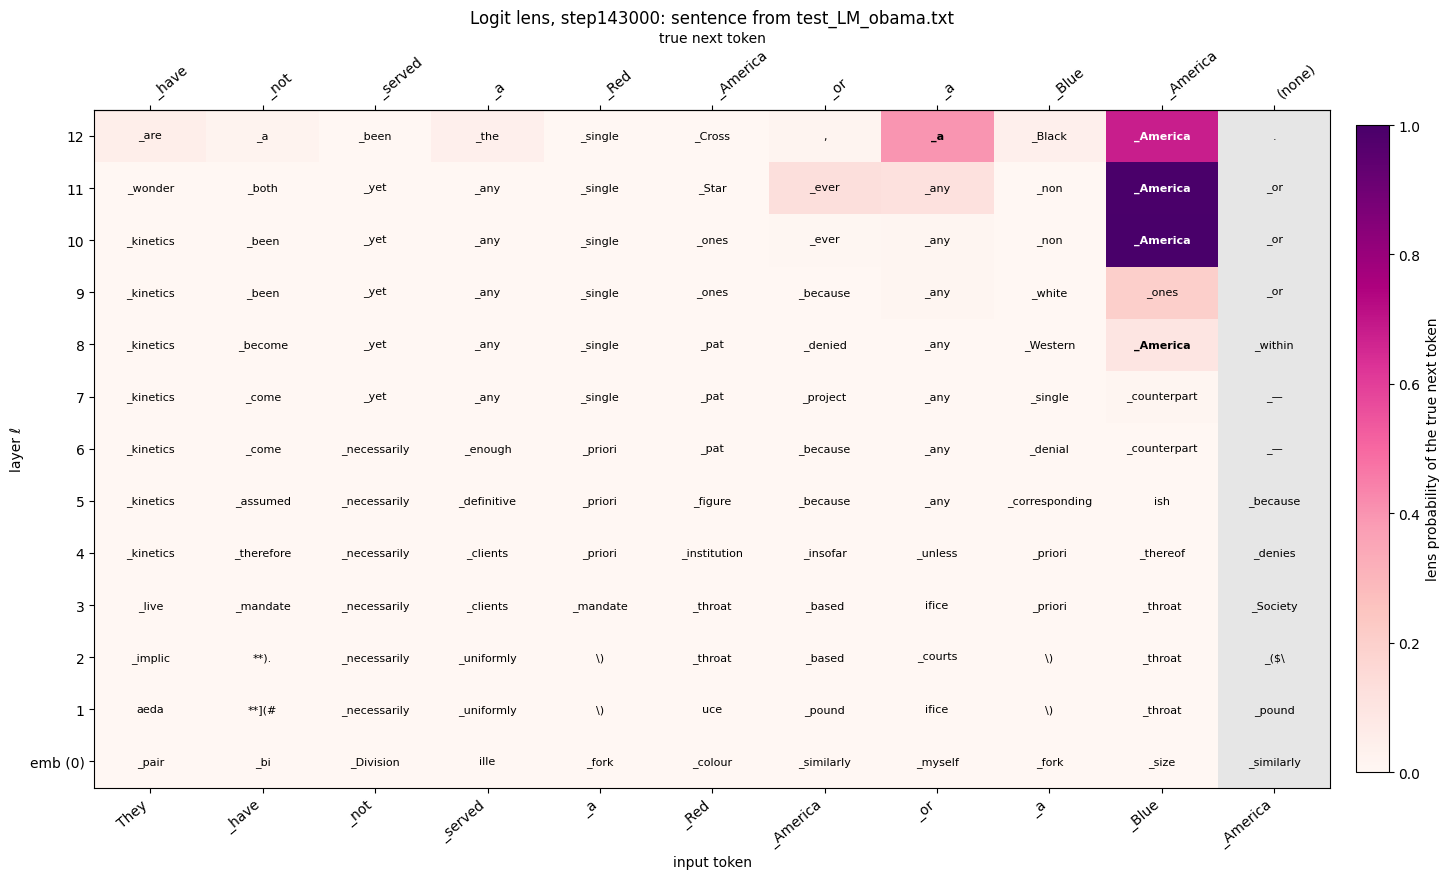

row 12 equals the model's real output (argmax of out.logits): True
pos         input     true next  p(true) @12  first layer top-1 = true  from there on
  0          They         _have        0.047                         -              -
  1         _have          _not        0.022                         -              -
  2          _not       _served        0.001                         -              -
  3       _served            _a        0.042                         -              -
  4            _a          _Red        0.000                         -              -
  5          _Red      _America        0.000                         -              -
  6      _America           _or        0.016                         -              -
  7           _or            _a        0.396                        12             12
  8            _a         _Blue        0.042                         -              -
  9         _Blue      _America        0.677                         8   

In [7]:
_ = plot_lens_grid(model, SENT_OBAMA, f"Logit lens, {FINAL}: sentence from test_LM_obama.txt")

**(ii) Grid for my own sentence:** *"India officially declared its independence from British colonial rule on August 15, 1947"* (final checkpoint, step143000).

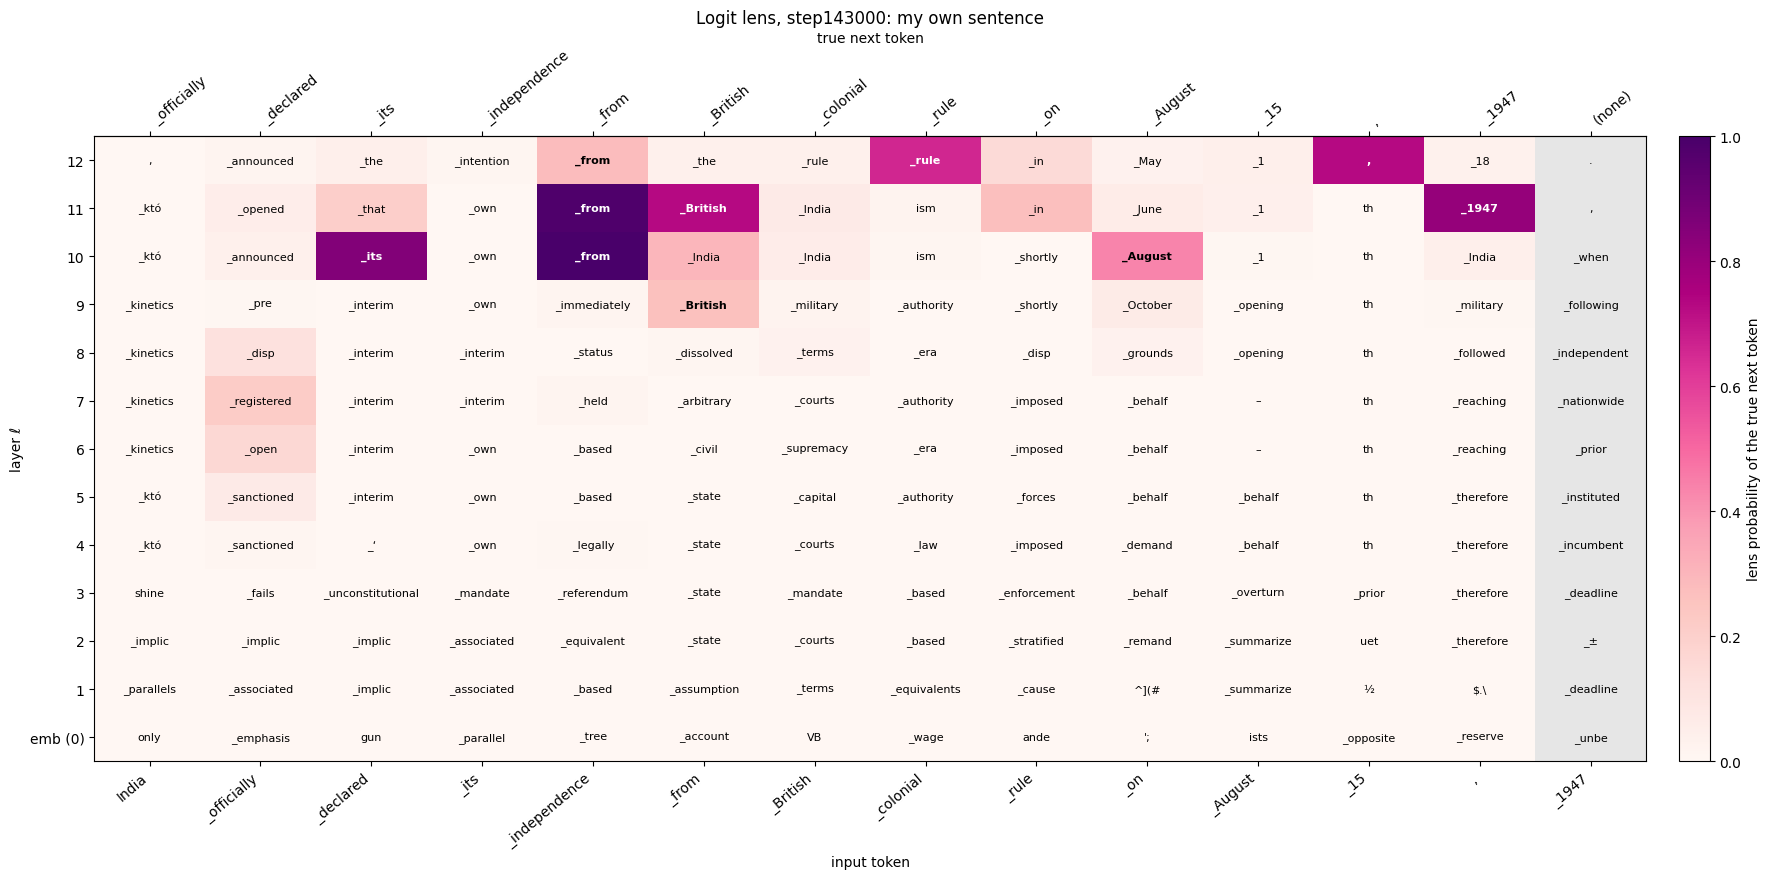

row 12 equals the model's real output (argmax of out.logits): True
pos         input     true next  p(true) @12  first layer top-1 = true  from there on
  0         India   _officially        0.000                         -              -
  1   _officially     _declared        0.019                         -              -
  2     _declared          _its        0.044                        10              -
  3          _its  _independence        0.008                         -              -
  4  _independence         _from        0.279                        10             10
  5         _from      _British        0.038                         9              -
  6      _British     _colonial        0.038                         -              -
  7     _colonial         _rule        0.660                        12             12
  8         _rule           _on        0.150                         -              -
  9           _on       _August        0.028                        10 

In [8]:
_ = plot_lens_grid(model, SENT_MINE, f"Logit lens, {FINAL}: my own sentence")

**(iii) Lens accuracy by layer over the whole of `test_LM_obama.txt`** (final checkpoint, step143000)

For every position in the file, the lens at layer $\ell$ is correct if its top-1 token equals the true next token.
Alongside the required accuracy, the cell also records the lens cross-entropy against the true next token, which is used in 3.2.2.

(2.3s)

Logit-lens top-1 accuracy for the true next token, step143000, test_LM_obama.txt (6014 predictions):
  layer  0: 0.0002   (1/6014)
  layer  6: 0.0672   (404/6014)
  layer 12: 0.3688   (2218/6014)

all layers: 0:0.0002 1:0.0116 2:0.0080 3:0.0146 4:0.0181 5:0.0479 6:0.0672 7:0.0870 8:0.0961 9:0.1084 10:0.2117 11:0.2677 12:0.3688


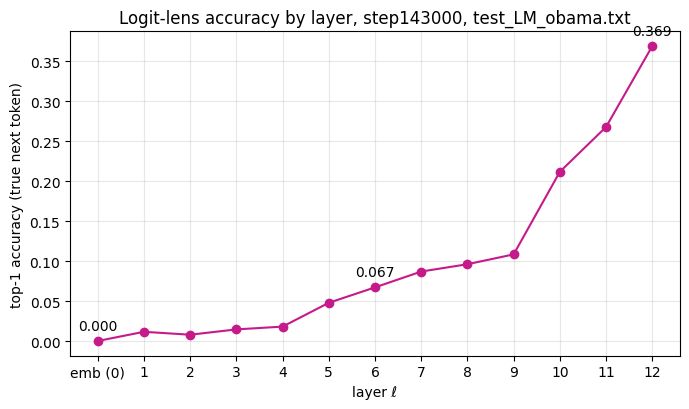

In [9]:
def lens_accuracy(model, chunks):
    """Top-1 accuracy (and cross-entropy) of the logit lens for the true next token, at every layer 0..N_LAYERS."""
    correct = np.zeros(N_LAYERS + 1, dtype=np.int64)
    ce = np.zeros(N_LAYERS + 1)
    agree_with_output, total = 0, 0
    for c in chunks:
        x = c[None].to(DEVICE)
        out = model(x, output_hidden_states=True)
        tgt = x[0, 1:]
        for l, h in enumerate(out.hidden_states):
            logits = lens(model, h[0, :-1], l)
            pred = logits.argmax(-1)
            correct[l] += (pred == tgt).sum().item()
            ce[l] += F.cross_entropy(logits, tgt, reduction="sum").item()
        agree_with_output += (pred == out.logits[0, :-1].argmax(-1)).sum().item()   # pred is layer 12 here
        total += tgt.numel()
    assert agree_with_output / total > 0.999, "layer-12 lens should reproduce the model's own predictions"
    return {"correct": correct, "acc": correct / total, "ce": ce / total, "n": total}


t0 = time.time()
lens_results = {FINAL: lens_accuracy(model, chunks)}
r = lens_results[FINAL]
print(f"({time.time() - t0:.1f}s)\n")
print(f"Logit-lens top-1 accuracy for the true next token, {FINAL}, test_LM_obama.txt ({r['n']} predictions):")
for l in (0, 6, 12):
    print(f"  layer {l:>2}: {r['acc'][l]:.4f}   ({r['correct'][l]}/{r['n']})")
print("\nall layers:", " ".join(f"{l}:{a:.4f}" for l, a in enumerate(r["acc"])))

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(range(N_LAYERS + 1), r["acc"], "o-", color="#c51b8a")
for l in (0, 6, 12):
    ax.annotate(f"{r['acc'][l]:.3f}", (l, r["acc"][l]), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_xticks(range(N_LAYERS + 1))
ax.set_xticklabels(["emb (0)"] + [str(l) for l in range(1, N_LAYERS + 1)])
ax.set_xlabel("layer ℓ")
ax.set_ylabel("top-1 accuracy (true next token)")
ax.set_title(f"Logit-lens accuracy by layer, {FINAL}, test_LM_obama.txt")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Answer 3.2.1

The plots and printed values are produced by the cells above.

- **(i) Grid for the Obama sentence.** The true next token becomes the top-1 prediction only in the top layers.
  - *Blue → America* first appears at layer 8 and is stable from layer 10 (probability 0.68 at layer 12).
  - *or → a* appears only at layer 12.
  - No other position is ever predicted correctly.
- **(ii) Grid for my sentence.**
  - *independence → from* is the top-1 prediction from layer 10 on (probability 0.28 at layer 12).
  - *colonial → rule* and *15 → ,* only become top-1 at layer 12 (probability 0.66 and 0.73).
  - Four other correct tokens appear in layers 9–11 and are lost again at layer 12: *declared → its* (layer 10), *from → British* (layer 9), *on → August* (layer 10) and *, → 1947* (layer 11). At layer 12 the model gives these true tokens only 0.03–0.04 probability.
  - The other positions are never top-1 correct.
- **(iii) Accuracy by layer.** The exact top-1 accuracies printed above, over 6,014 predictions, are:

| Layer | Accuracy | Correct |
|---|---|---|
| 0 | 0.0002 | 1 / 6,014 |
| 6 | 0.0672 | 404 / 6,014 |
| 12 | 0.3688 | 2,218 / 6,014 |

  Accuracy stays below 0.11 up to layer 9, then rises steeply over the last three layers: 0.21, 0.27 and 0.37.

### 3.2.2 Across training (Gradescope 4.2, 13 pts)

> **Question.** Repeat the accuracy-by-layer curve at step512, step1000, step8000 and step143000 on the same axes. In a Markdown text cell below the plot, answer: do the middle layers become more or less readable as training goes on? Explain what you find. What does it suggest about whether the hidden states in the middle of the network are in the same "language" as the output layer? (The tuned lens of Belrose et al. is worth a look.)

**The plot.**
- **Left panel:** the required plot, with accuracy by layer at the four checkpoints on the same axes.
- **Middle panel:** each curve divided by that checkpoint's own layer-12 accuracy. This separates "the middle layers are more readable" from "the whole model got better".
- **Right panel:** the lens cross-entropy for the true next token (lower = more readable).

model.safetensors: reconstructing file:   0%|          |  0.00B /  649MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

loaded step512 on cuda in 7.6s
   lens accuracy computed in 2.2s


model.safetensors: reconstructing file:   0%|          |  0.00B /  649MB            

model.safetensors: downloading bytes:           |  0.00B            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  649MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

loaded step8000 on cuda in 7.6s
   lens accuracy computed in 2.3s


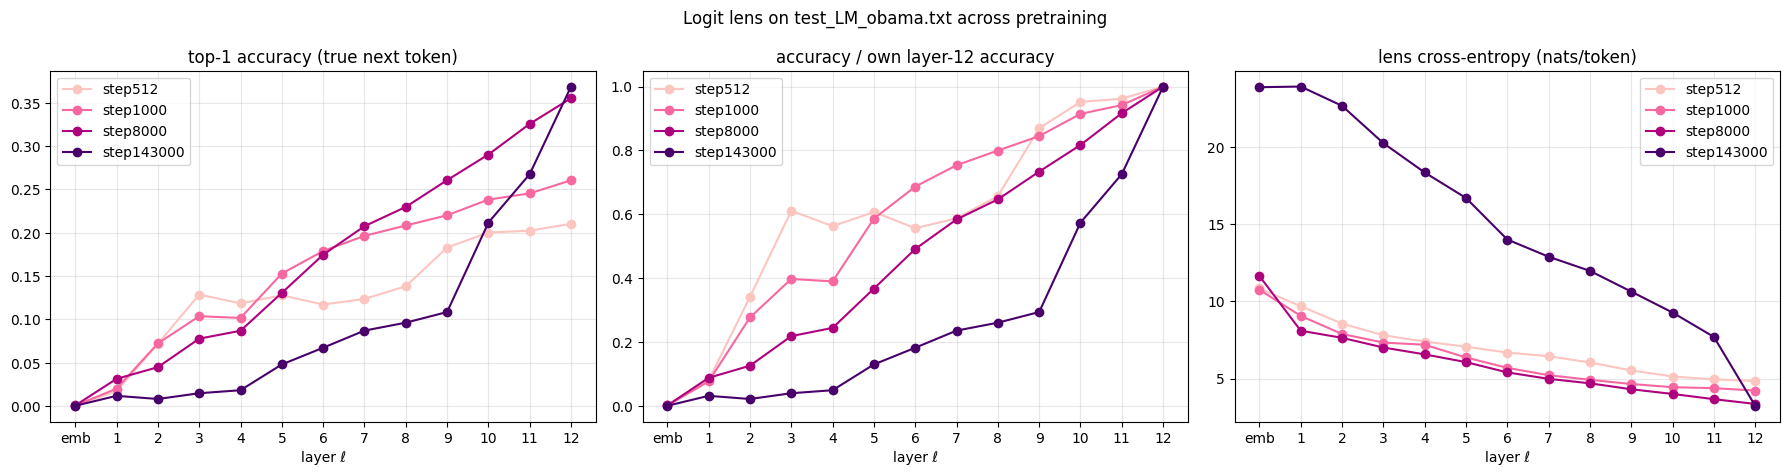

top-1 accuracy by layer
 layer     step512    step1000    step8000  step143000
     0      0.0005      0.0003      0.0005      0.0002
     1      0.0170      0.0200      0.0313      0.0116
     2      0.0718      0.0722      0.0447      0.0080
     3      0.1285      0.1036      0.0777      0.0146
     4      0.1184      0.1016      0.0868      0.0181
     5      0.1277      0.1528      0.1305      0.0479
     6      0.1171      0.1789      0.1746      0.0672
     7      0.1235      0.1964      0.2075      0.0870
     8      0.1382      0.2083      0.2298      0.0961
     9      0.1829      0.2202      0.2607      0.1084
    10      0.2002      0.2383      0.2903      0.2117
    11      0.2024      0.2454      0.3257      0.2677
    12      0.2103      0.2606      0.3553      0.3688

accuracy relative to the same checkpoint's layer 12
 layer     step512    step1000    step8000  step143000
     0       0.002       0.001       0.001       0.000
     1       0.081       0.077       0.088 

In [10]:
CURVE_STEPS = ["step512", "step1000", "step8000", FINAL]
for rev in CURVE_STEPS:
    if rev in lens_results:
        continue
    m = load_model(rev)
    t0 = time.time()
    lens_results[rev] = lens_accuracy(m, chunks)
    print(f"   lens accuracy computed in {time.time() - t0:.1f}s")
    del m
    free_memory()

layers = np.arange(N_LAYERS + 1)
colors = {"step512": "#fcc5c0", "step1000": "#f768a1", "step8000": "#ae017e", FINAL: "#49006a"}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for rev in CURVE_STEPS:
    r = lens_results[rev]
    axes[0].plot(layers, r["acc"], "o-", color=colors[rev], label=rev)
    axes[1].plot(layers, r["acc"] / r["acc"][-1], "o-", color=colors[rev], label=rev)
    axes[2].plot(layers, r["ce"], "o-", color=colors[rev], label=rev)
titles = ["top-1 accuracy (true next token)", "accuracy / own layer-12 accuracy", "lens cross-entropy (nats/token)"]
for ax, t in zip(axes, titles):
    ax.set_xticks(layers)
    ax.set_xticklabels(["emb"] + [str(l) for l in layers[1:]])
    ax.set_xlabel("layer ℓ")
    ax.set_title(t)
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("Logit lens on test_LM_obama.txt across pretraining")
plt.tight_layout()
plt.show()

print("top-1 accuracy by layer")
print(f"{'layer':>6} " + " ".join(f"{rev:>11}" for rev in CURVE_STEPS))
for l in layers:
    print(f"{l:>6} " + " ".join(f"{lens_results[rev]['acc'][l]:>11.4f}" for rev in CURVE_STEPS))
print("\naccuracy relative to the same checkpoint's layer 12")
print(f"{'layer':>6} " + " ".join(f"{rev:>11}" for rev in CURVE_STEPS))
for l in layers:
    print(f"{l:>6} " + " ".join(f"{lens_results[rev]['acc'][l] / lens_results[rev]['acc'][-1]:>11.3f}" for rev in CURVE_STEPS))
print("\nlens cross-entropy by layer (nats/token)")
print(f"{'layer':>6} " + " ".join(f"{rev:>11}" for rev in CURVE_STEPS))
for l in layers:
    print(f"{l:>6} " + " ".join(f"{lens_results[rev]['ce'][l]:>11.3f}" for rev in CURVE_STEPS))

#### Answer 3.2.2

**(a) Do the middle layers become more or less readable as training goes on?**

**Less readable.** The model's final prediction improves with training, but the logit lens reads the middle layers *worse*, not better.

**(b) What I find.**

- **Earlier checkpoints are more readable in the middle.** All three earlier checkpoints beat the final model at every layer from 1 to 9. For example, at layer 6 the accuracy is 0.117 / 0.179 / 0.175 at step512 / 1000 / 8000, against 0.067 at step143000. step8000 beats step143000 at every layer up to 11 (layer 9: 0.261 vs 0.108); the final model only pulls ahead of it at the top layer (0.369 vs 0.355).
- **The final model reaches its prediction late.** Relative to each checkpoint's own layer 12 (middle panel), layer 6 reaches 0.56, 0.69 and 0.49 of the final accuracy at the earlier checkpoints, but only 0.18 at step143000. The final model stays below 0.30 up to layer 9, then jumps to 0.57 at layer 10 and 0.73 at layer 11. The grids show the same: in neither sentence does a correct prediction appear before layer 8. *Blue → America* appears at layer 8 (stable from 10), *independence → from* from layer 10, and *or → a*, *colonial → rule* and *15 → ,* only at layer 12.
- **The final model's middle layers are confidently wrong.** Guessing uniformly over 50,304 tokens costs ln 50304 ≈ 10.83 nats. The early checkpoints start near that at layer 0 (10.8–11.6 nats) and improve steadily up the network: from layer 1 on, their lens cross-entropy is always below it. The final model's lens is *worse than a uniform guess* at every layer up to 8: 23.9 nats at layers 0–1, 14.0 at layer 6, 12.0 at layer 8. It only drops to 3.23 at layer 12. So its middle-layer readouts are not just uninformative; they put high probability on the wrong tokens. A related sign appears at the first position of both grids: the middle layers read out the same few unrelated tokens whatever the word is (*_kinetics* at layers 4–10 for *They*; *_kinetics* or *_któ* at layers 4–11 for *India*).

**(c) Are the middle hidden states in the same "language" as the output layer?**

**No.** Early in training, every layer writes directly in the output "language": the network is mostly learning token statistics, each layer nudges the prediction, and $W_U$ can read every layer. As training goes on, the middle layers carry features that later layers use but that are not aligned with the directions $W_U$ reads. So the middle hidden states are *not* in the same language as the output layer, and the last two or three layers translate them into output space (the big jumps at layers 10–12).

This does not mean the information is missing. Belrose et al. (the tuned lens) learn a separate affine "translator" for each layer and read much better predictions from intermediate layers than the logit lens does, which points to a change of basis between layers rather than an absence of information. The logit lens only measures how close a layer is to the output basis, and in the fully trained model the middle layers are far from it.

## 3.3 Transplanting Layers Across Time (Gradescope item 5, 20 pts)

> **Question.** Pretraining changes every weight a little at a time, one gradient step after another. Are the layers of the final model still compatible with their younger selves?
>
> Take the final checkpoint and replace one component (the embedding, a single layer, or the unembedding) with the same component from a donor checkpoint, leaving everything else untouched. Use donors step0, step1000, step8000 and step32000. For each (component, donor) pair, measure the change in test loss on `test_LM_obama.txt`. Each transplant must start from the intact final model: restore the original weights (or work on a fresh copy) before the next one.
>
> Show your results as a component × donor heatmap. Use a log colour scale, since some cells are far larger than others (clip small or negative changes to the bottom of the scale), and print the exact values in the heatmap cells.
>
> In a Markdown cell below the heatmap, answer: which components can the model lose (replaced by random step0 weights) with little damage, and which are irreplaceable? Does a later donor always hurt less than an earlier one? Explain what you find, in particular any component where a later donor hurts more. Back every claim with a number from your heatmap or with an additional plot of your own.

**What the code does.**
- It starts from the intact final model (`step143000`) and replaces **one** component with the same component from a donor checkpoint (`step0`, `step1000`, `step8000`, `step32000`).
- It measures the change in mean test loss (nats/token) on `test_LM_obama.txt`.
- It puts the original weights back before the next transplant.

Components:
- `emb`: the token embedding matrix `embed_in`.
- `layer i`: the whole transformer block *i* (its two LayerNorms, attention and MLP).
- `unemb`: the unembedding matrix (`embed_out` / `lm_head`).

The final layer norm always stays from `step143000`. The heatmap is right after the transplant code. The extra plots and the extra experiment below it back up the answer at the end of this section.

In [11]:
COMPONENTS = ["emb"] + [f"layer {i}" for i in range(N_LAYERS)] + ["unemb"]
DONORS = ["step0", "step1000", "step8000", "step32000"]


def component(model, name):
    if name == "emb":
        return W_E(model)
    if name == "unemb":
        return W_U(model)
    return blocks(model)[int(name.split()[1])]


def test_loss(model, chunks):
    """Mean next-token cross-entropy (nats/token) over the whole file."""
    total, n = 0.0, 0
    for c in chunks:
        x = c[None].to(DEVICE)
        logits = model(x).logits[0, :-1]
        total += F.cross_entropy(logits, x[0, 1:], reduction="sum").item()
        n += x.shape[1] - 1
    return total / n


base_loss = test_loss(model, chunks)
x = chunks[0][None].to(DEVICE)
print(f"check on chunk 0: own loss {test_loss(model, chunks[:1]):.6f} vs out.loss {model(x, labels=x).loss.item():.6f}")
print(f"intact {FINAL}: test loss {base_loss:.4f} nats/token (perplexity {np.exp(base_loss):.2f}) over {N_PRED} tokens")

# Snapshot of every component of the intact final model, kept on the CPU, so each transplant starts from it.
original = {name: {k: v.detach().cpu().clone() for k, v in component(model, name).state_dict().items()}
            for name in COMPONENTS}


def check_intact(model):
    for name in COMPONENTS:
        for k, v in component(model, name).state_dict().items():
            assert torch.equal(v.cpu(), original[name][k]), f"{name}.{k} was not restored"

check on chunk 0: own loss 3.272283 vs out.loss 3.272283
intact step143000: test loss 3.2330 nats/token (perplexity 25.36) over 6014 tokens


In [12]:
delta = np.zeros((len(COMPONENTS), len(DONORS)))     # change in test loss
rel_dist = np.zeros((len(COMPONENTS), len(DONORS)))  # ||W_donor - W_final|| / ||W_final|| over the component's parameters

t0 = time.time()
for j, rev in enumerate(DONORS):
    donor = load_model(rev, device="cpu")           # only its weights are needed
    for i, name in enumerate(COMPONENTS):
        donor_part = component(donor, name)
        p_final = {k: v for k, v in original[name].items() if v.is_floating_point()}
        p_donor = dict(donor_part.named_parameters())
        num = sum(((p_donor[k].float() - p_final[k]) ** 2).sum().item() for k in p_donor)
        den = sum((p_final[k] ** 2).sum().item() for k in p_donor)
        rel_dist[i, j] = np.sqrt(num / den)

        component(model, name).load_state_dict(donor_part.state_dict())   # transplant
        delta[i, j] = test_loss(model, chunks) - base_loss
        component(model, name).load_state_dict(original[name])            # put the original back
    del donor
    free_memory()
    check_intact(model)
    restored = test_loss(model, chunks)
    assert abs(restored - base_loss) < 1e-4
    print(f"   donor {rev}: 14 transplants done, model restored (loss {restored:.6f} = base {base_loss:.6f})")
print(f"total {time.time() - t0:.1f}s")

model.safetensors: reconstructing file:   0%|          |  0.00B /  649MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

loaded step0 on cpu in 9.6s
   donor step0: 14 transplants done, model restored (loss 3.233027 = base 3.233027)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

loaded step1000 on cpu in 0.3s
   donor step1000: 14 transplants done, model restored (loss 3.233027 = base 3.233027)


... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  649MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

loaded step32000 on cpu in 8.5s
   donor step32000: 14 transplants done, model restored (loss 3.233027 = base 3.233027)
total 65.2s


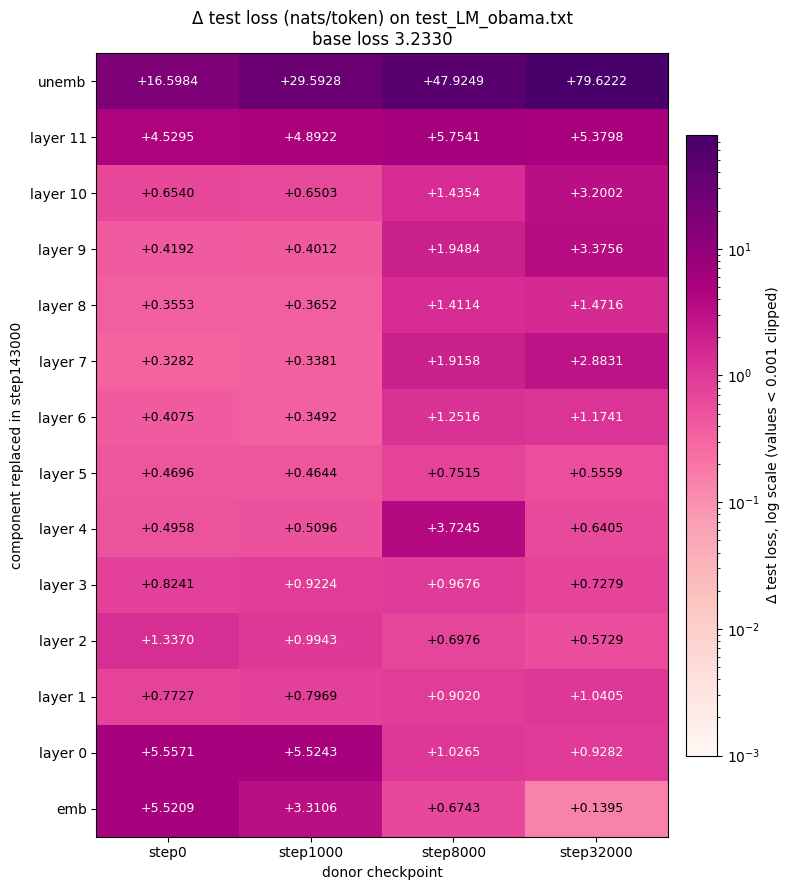

base loss 3.2330 nats/token, perplexity 25.36

Δ test loss (nats/token)
 component       step0    step1000    step8000   step32000
     unemb    +16.5984    +29.5928    +47.9249    +79.6222
  layer 11     +4.5295     +4.8922     +5.7541     +5.3798
  layer 10     +0.6540     +0.6503     +1.4354     +3.2002
   layer 9     +0.4192     +0.4012     +1.9484     +3.3756
   layer 8     +0.3553     +0.3652     +1.4114     +1.4716
   layer 7     +0.3282     +0.3381     +1.9158     +2.8831
   layer 6     +0.4075     +0.3492     +1.2516     +1.1741
   layer 5     +0.4696     +0.4644     +0.7515     +0.5559
   layer 4     +0.4958     +0.5096     +3.7245     +0.6405
   layer 3     +0.8241     +0.9224     +0.9676     +0.7279
   layer 2     +1.3370     +0.9943     +0.6976     +0.5729
   layer 1     +0.7727     +0.7969     +0.9020     +1.0405
   layer 0     +5.5571     +5.5243     +1.0265     +0.9282
       emb     +5.5209     +3.3106     +0.6743     +0.1395

perplexity after the transplant
 component

In [13]:
VMIN = 1e-3                                           # changes below this (including negative ones) sit at the bottom of the scale
vmax = max(delta.max(), 10 * VMIN)
shown = np.clip(delta, VMIN, None)
norm = LogNorm(vmin=VMIN, vmax=vmax)

fig, ax = plt.subplots(figsize=(8, 9))
im = ax.imshow(shown, norm=norm, cmap="RdPu", origin="lower", aspect="auto")
for i in range(len(COMPONENTS)):
    for j in range(len(DONORS)):
        frac = (np.log(shown[i, j]) - np.log(VMIN)) / (np.log(vmax) - np.log(VMIN))
        ax.text(j, i, f"{delta[i, j]:+.4f}", ha="center", va="center", fontsize=9,
                color="white" if frac > 0.6 else "black")
ax.set_xticks(range(len(DONORS)))
ax.set_xticklabels(DONORS)
ax.set_yticks(range(len(COMPONENTS)))
ax.set_yticklabels(COMPONENTS)
ax.set_xlabel("donor checkpoint")
ax.set_ylabel(f"component replaced in {FINAL}")
ax.set_title(f"Δ test loss (nats/token) on test_LM_obama.txt\nbase loss {base_loss:.4f}")
fig.colorbar(im, ax=ax, fraction=0.05, pad=0.03, label=f"Δ test loss, log scale (values < {VMIN:g} clipped)")
plt.tight_layout()
plt.show()

print(f"base loss {base_loss:.4f} nats/token, perplexity {np.exp(base_loss):.2f}\n")
print("Δ test loss (nats/token)")
print(f"{'component':>10} " + " ".join(f"{d:>11}" for d in DONORS))
for i, name in reversed(list(enumerate(COMPONENTS))):
    print(f"{name:>10} " + " ".join(f"{delta[i, j]:>+11.4f}" for j in range(len(DONORS))))
print("\nperplexity after the transplant")
print(f"{'component':>10} " + " ".join(f"{d:>11}" for d in DONORS))
for i, name in reversed(list(enumerate(COMPONENTS))):
    print(f"{name:>10} " + " ".join(f"{np.exp(base_loss + delta[i, j]):>11.2f}" for j in range(len(DONORS))))

#### Extra evidence

Two extra views of the same data:

- **Left:** how far each component's weights moved between the donor and the final model, as $\lVert W_\text{donor} - W_\text{final}\rVert / \lVert W_\text{final}\rVert$.
- **Right:** Δ loss for each component as a function of the donor step.

The printout lists every case where a *later* donor hurts *more* than an earlier one.

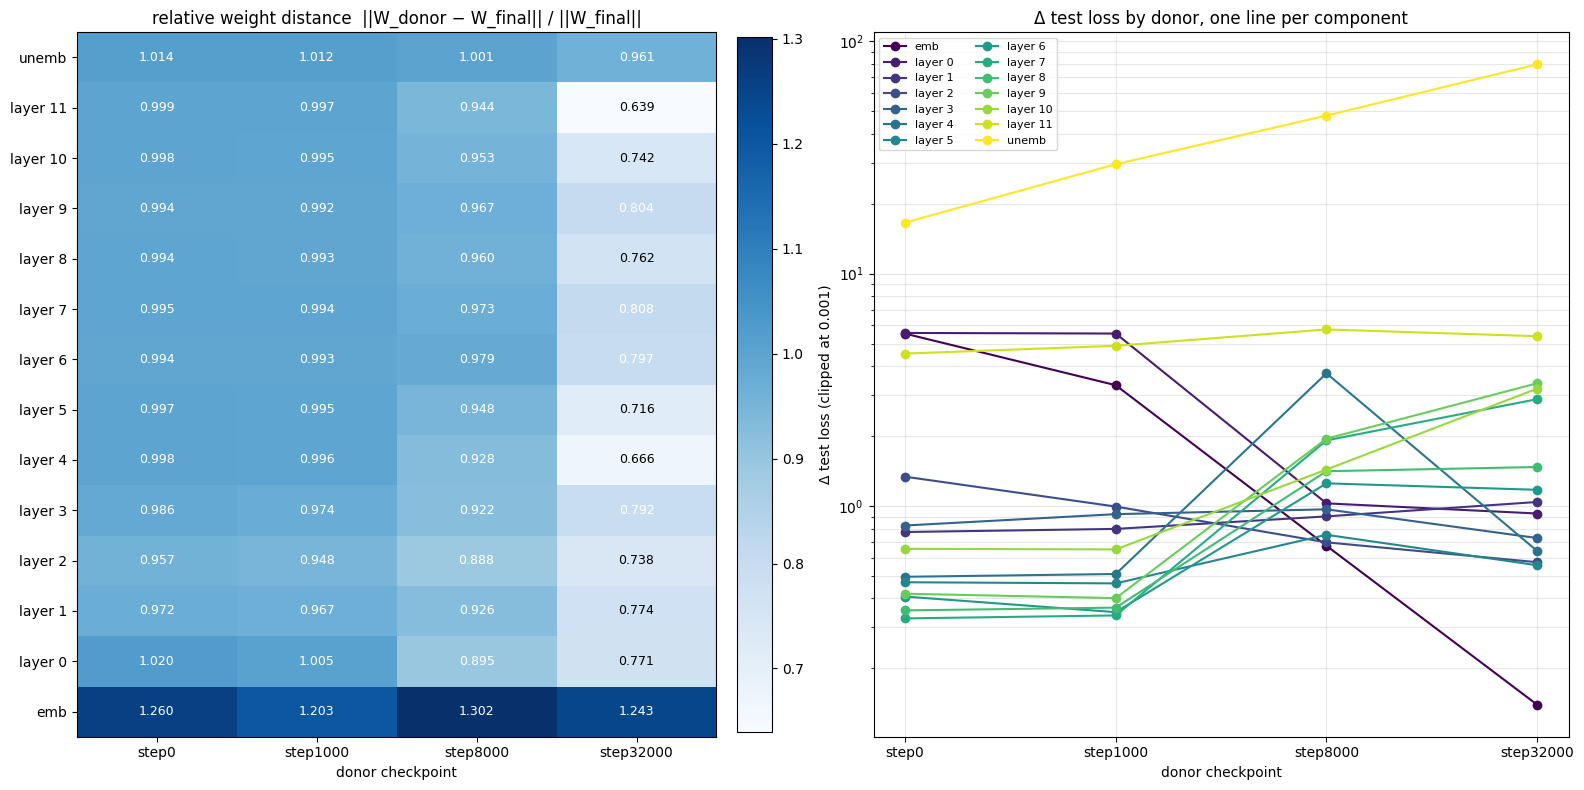

Components ranked by damage when replaced with random step0 weights:
    layer 7: +0.3282
    layer 8: +0.3553
    layer 6: +0.4075
    layer 9: +0.4192
    layer 5: +0.4696
    layer 4: +0.4958
   layer 10: +0.6540
    layer 1: +0.7727
    layer 3: +0.8241
    layer 2: +1.3370
   layer 11: +4.5295
        emb: +5.5209
    layer 0: +5.5571
      unemb: +16.5984

Δ test loss by donor; ↑ marks a donor that hurts more than the previous (earlier) donor by more than 0.001:
        emb: step0  +5.5209     step1000  +3.3106     step8000  +0.6743     step32000  +0.1395  
    layer 0: step0  +5.5571     step1000  +5.5243     step8000  +1.0265     step32000  +0.9282  
    layer 1: step0  +0.7727     step1000  +0.7969 ↑   step8000  +0.9020 ↑   step32000  +1.0405 ↑   worse than step0: step1000, step8000, step32000
    layer 2: step0  +1.3370     step1000  +0.9943     step8000  +0.6976     step32000  +0.5729  
    layer 3: step0  +0.8241     step1000  +0.9224 ↑   step8000  +0.9676 ↑   step32000  +0

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
im = axes[0].imshow(rel_dist, cmap="Blues", origin="lower", aspect="auto")
for i in range(len(COMPONENTS)):
    for j in range(len(DONORS)):
        axes[0].text(j, i, f"{rel_dist[i, j]:.3f}", ha="center", va="center", fontsize=9,
                     color="white" if rel_dist[i, j] > 0.6 * rel_dist.max() else "black")
axes[0].set_xticks(range(len(DONORS)))
axes[0].set_xticklabels(DONORS)
axes[0].set_yticks(range(len(COMPONENTS)))
axes[0].set_yticklabels(COMPONENTS)
axes[0].set_xlabel("donor checkpoint")
axes[0].set_title("relative weight distance  ||W_donor − W_final|| / ||W_final||")
fig.colorbar(im, ax=axes[0], fraction=0.05, pad=0.03)

steps = [int(d.replace("step", "")) for d in DONORS]
xpos = np.arange(len(DONORS))
cm = plt.get_cmap("viridis")
for i, name in enumerate(COMPONENTS):
    axes[1].plot(xpos, np.clip(delta[i], VMIN, None), "o-", color=cm(i / (len(COMPONENTS) - 1)), label=name)
axes[1].set_yscale("log")
axes[1].set_xticks(xpos)
axes[1].set_xticklabels(DONORS)
axes[1].set_xlabel("donor checkpoint")
axes[1].set_ylabel(f"Δ test loss (clipped at {VMIN:g})")
axes[1].set_title("Δ test loss by donor, one line per component")
axes[1].grid(alpha=0.3, which="both")
axes[1].legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

print("Components ranked by damage when replaced with random step0 weights:")
for i in np.argsort(delta[:, 0]):
    print(f"  {COMPONENTS[i]:>9}: {delta[i, 0]:+.4f}")

TOL = 1e-3   # ignore differences smaller than 0.001 nats/token
print(f"\nΔ test loss by donor; ↑ marks a donor that hurts more than the previous (earlier) donor by more than {TOL:g}:")
for i, name in enumerate(COMPONENTS):
    parts = [f"{DONORS[j]} {delta[i, j]:+8.4f}{' ↑' if j > 0 and delta[i, j] > delta[i, j - 1] + TOL else '  '}"
             for j in range(len(DONORS))]
    worse = [DONORS[j] for j in range(1, len(DONORS)) if delta[i, j] > delta[i, 0] + TOL]
    print(f"  {name:>9}: " + "   ".join(parts) + (f"   worse than step0: {', '.join(worse)}" if worse else ""))

#### Extra experiment: why can a trained donor hurt more than a random one?

Three measurements to explain the heatmap.

- **Skipping a layer.** A forward hook replaces layer *i*'s output with its input, so the layer adds nothing to the residual stream. If putting in a step0 layer costs about as much as skipping it, the random layer is effectively doing nothing.
- **What the transplanted layer writes.** Every earlier layer is unchanged, so a transplanted layer *i* receives exactly the same input as the original layer *i*. We compare what each adds to the residual stream (output − input) at every token of the test file:
  - the ratio of the mean norms, donor / original (scale);
  - the mean cosine similarity per token (direction).
- **Weight size and direction.** For every component, $\lVert W_\text{donor}\rVert / \lVert W_\text{final}\rVert$ and the cosine between the flattened weight matrices (biases and LayerNorm gains left out). This separates "different size" from "different direction" in the weight-distance plot above.

For the unembedding transplants, we also record the mean entropy of the predicted next-token distribution and the probability given to the true token.

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

loaded step0 on cpu in 0.3s


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

loaded step1000 on cpu in 0.3s


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

loaded step8000 on cpu in 0.3s


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

loaded step32000 on cpu in 0.3s
done in 57.3s; model intact again (loss 3.233027 = base 3.233027)

Δ test loss per layer: skipping the layer vs transplanting it
 layer      skip      step0   step1000   step8000  step32000
     0   +5.6939    +5.5571    +5.5243    +1.0265    +0.9282
     1   +0.6034    +0.7727    +0.7969    +0.9020    +1.0405
     2   +1.2156    +1.3370    +0.9943    +0.6976    +0.5729
     3   +0.7505    +0.8241    +0.9224    +0.9676    +0.7279
     4   +0.4318    +0.4958    +0.5096    +3.7245    +0.6405
     5   +0.3905    +0.4696    +0.4644    +0.7515    +0.5559
     6   +0.3245    +0.4075    +0.3492    +1.2516    +1.1741
     7   +0.2785    +0.3282    +0.3381    +1.9158    +2.8831
     8   +0.2659    +0.3553    +0.3652    +1.4114    +1.4716
     9   +0.3736    +0.4192    +0.4012    +1.9484    +3.3756
    10   +0.6349    +0.6540    +0.6503    +1.4354    +3.2002
    11   +4.4642    +4.5295    +4.8922    +5.7541    +5.3798

What the transplanted layer writes into the r

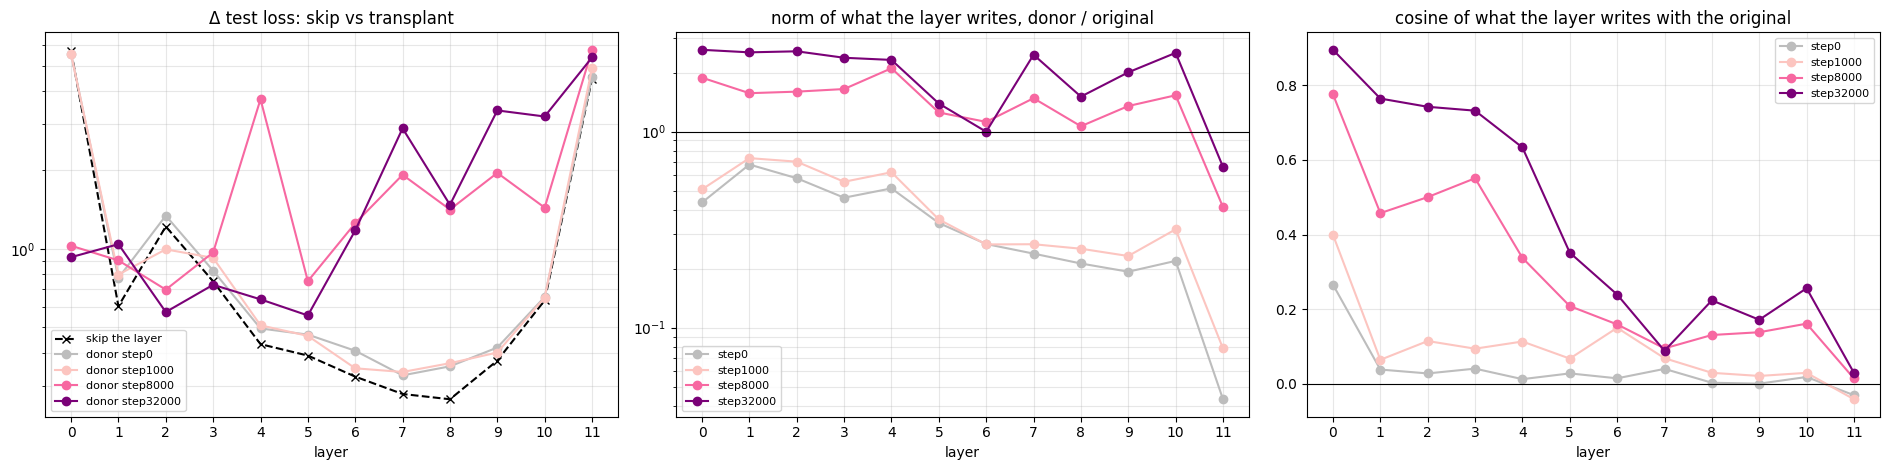

In [15]:

def _layer_input(args, kwargs):
    return args[0] if args else kwargs["hidden_states"]


def _layer_output(output):
    return output[0] if isinstance(output, tuple) else output


def skip_layer_hook(module, args, kwargs, output):
    """Replace the layer's output with its input, so the layer adds nothing to the residual stream."""
    h_in = _layer_input(args, kwargs)
    return (h_in,) + tuple(output[1:]) if isinstance(output, tuple) else h_in


def layer_writes(model, i):
    """What layer i adds to the residual stream (output - input) at every token of the test file: [N, d] on the CPU."""
    writes = []

    def hook(module, args, kwargs, output):
        writes.append((_layer_output(output) - _layer_input(args, kwargs))[0].float().cpu())

    handle = blocks(model)[i].register_forward_hook(hook, with_kwargs=True)
    try:
        for c in chunks:
            model(c[None].to(DEVICE))
    finally:
        handle.remove()
    return torch.cat(writes)


def prediction_stats(model):
    """Mean entropy (nats) of the next-token distribution and mean probability of the true next token."""
    ent, p_true, n = 0.0, 0.0, 0
    for c in chunks:
        x = c[None].to(DEVICE)
        logp = model(x).logits[0, :-1].float().log_softmax(-1)
        ent += -(logp.exp() * logp).sum(-1).sum().item()
        p_true += logp.gather(1, x[0, 1:, None]).exp().sum().item()
        n += x.shape[1] - 1
    return ent / n, p_true / n


t0 = time.time()
# 1) skipping each layer
skip_delta = np.zeros(N_LAYERS)
for i in range(N_LAYERS):
    handle = blocks(model)[i].register_forward_hook(skip_layer_hook, with_kwargs=True)
    try:
        skip_delta[i] = test_loss(model, chunks) - base_loss
    finally:
        handle.remove()

# 2) what each original layer writes, and the intact model's prediction statistics
orig_writes = [layer_writes(model, i) for i in range(N_LAYERS)]
base_entropy, base_p_true = prediction_stats(model)

# 3) donors: weight size/direction for every component, layer writes, unembedding prediction statistics
write_ratio = np.zeros((N_LAYERS, len(DONORS)))
write_cos = np.zeros((N_LAYERS, len(DONORS)))
norm_ratio = np.zeros((len(COMPONENTS), len(DONORS)))
weight_cos = np.zeros((len(COMPONENTS), len(DONORS)))
unemb_stats = []
for j, rev in enumerate(DONORS):
    donor = load_model(rev, device="cpu")
    for i, name in enumerate(COMPONENTS):
        donor_part = component(donor, name)
        names = [k for k, p in donor_part.named_parameters() if p.dim() == 2]   # weight matrices only
        w_d = torch.cat([dict(donor_part.named_parameters())[k].detach().float().flatten() for k in names])
        w_f = torch.cat([original[name][k].float().flatten() for k in names])
        norm_ratio[i, j] = (w_d.norm() / w_f.norm()).item()
        weight_cos[i, j] = F.cosine_similarity(w_d, w_f, dim=0).item()
        if name.startswith("layer") or name == "unemb":
            component(model, name).load_state_dict(donor_part.state_dict())       # transplant
            if name == "unemb":
                unemb_stats.append(prediction_stats(model))
            else:
                L = int(name.split()[1])
                w = layer_writes(model, L)
                write_ratio[L, j] = (w.norm(dim=-1).mean() / orig_writes[L].norm(dim=-1).mean()).item()
                write_cos[L, j] = F.cosine_similarity(w, orig_writes[L], dim=-1).mean().item()
            component(model, name).load_state_dict(original[name])                # put the original back
    del donor
    free_memory()
check_intact(model)
print(f"done in {time.time() - t0:.1f}s; model intact again (loss {test_loss(model, chunks):.6f} = base {base_loss:.6f})\n")

print("Δ test loss per layer: skipping the layer vs transplanting it")
print(f"{'layer':>6}  {'skip':>8}  " + "  ".join(f"{d:>9}" for d in DONORS))
for i in range(N_LAYERS):
    print(f"{i:>6}  {skip_delta[i]:>+8.4f}  " + "  ".join(f"{delta[i + 1, j]:>+9.4f}" for j in range(len(DONORS))))

print("\nWhat the transplanted layer writes into the residual stream, relative to the original layer")
print(f"{'':>6}  {'norm ratio (donor / original)':^43}    {'mean cosine with the original write':^43}")
print(f"{'layer':>6}  " + "  ".join(f"{d:>9}" for d in DONORS) + "    " + "  ".join(f"{d:>9}" for d in DONORS))
for i in range(N_LAYERS):
    print(f"{i:>6}  " + "  ".join(f"{write_ratio[i, j]:>9.3f}" for j in range(len(DONORS))) + "    "
          + "  ".join(f"{write_cos[i, j]:>9.3f}" for j in range(len(DONORS))))

print("\nWeight matrices: norm ratio ||W_donor|| / ||W_final||  and  cosine(W_donor, W_final)")
print(f"{'component':>10}  " + "  ".join(f"{d:>9}" for d in DONORS) + "    " + "  ".join(f"{d:>9}" for d in DONORS))
for i, name in reversed(list(enumerate(COMPONENTS))):
    print(f"{name:>10}  " + "  ".join(f"{norm_ratio[i, j]:>9.3f}" for j in range(len(DONORS))) + "    "
          + "  ".join(f"{weight_cos[i, j]:>9.3f}" for j in range(len(DONORS))))

print(f"\nUnembedding transplants: mean entropy of the prediction and mean probability of the true next token")
print(f"{'intact':>10}: entropy {base_entropy:6.3f} nats   p(true) {base_p_true:.4f}")
for j, rev in enumerate(DONORS):
    print(f"{rev:>10}: entropy {unemb_stats[j][0]:6.3f} nats   p(true) {unemb_stats[j][1]:.2e}   Δ loss {delta[-1, j]:+.4f}")

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
layers_x = np.arange(N_LAYERS)
dcolors = {"step0": "#bdbdbd", "step1000": "#fcc5c0", "step8000": "#f768a1", "step32000": "#7a0177"}
axes[0].plot(layers_x, np.clip(skip_delta, VMIN, None), "k--", marker="x", label="skip the layer")
for j, rev in enumerate(DONORS):
    axes[0].plot(layers_x, np.clip(delta[1:N_LAYERS + 1, j], VMIN, None), "o-", color=dcolors[rev], label=f"donor {rev}")
    axes[1].plot(layers_x, write_ratio[:, j], "o-", color=dcolors[rev], label=rev)
    axes[2].plot(layers_x, write_cos[:, j], "o-", color=dcolors[rev], label=rev)
axes[0].set_yscale("log")
axes[0].set_title("Δ test loss: skip vs transplant")
axes[1].set_yscale("log")
axes[1].axhline(1, color="k", lw=0.8)
axes[1].set_title("norm of what the layer writes, donor / original")
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_title("cosine of what the layer writes with the original")
for ax in axes:
    ax.set_xticks(layers_x)
    ax.set_xlabel("layer")
    ax.grid(alpha=0.3, which="both")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


#### Answer 3.3

**(a) Which components can the model lose with little damage (replaced by random step0 weights), and which are irreplaceable?**

Replacing a component with random `step0` weights shows a clear split (base loss 3.233 nats, perplexity 25.4):

- **Cheap to lose: the middle layers.** Layers 4–9 cost only +0.33 to +0.50 nats; layer 7 is the cheapest at +0.33. Perplexity rises from 25.4 to just 35–42. Layers 10, 1 and 3 cost +0.65 to +0.82, and layer 2 costs +1.34.
- **Skipping a layer costs about the same.** In the extra experiment, skipping layers 4–9 entirely costs only +0.27 to +0.43.
- **Irreplaceable: the four components at the two ends of the network.**

| Component | Δ loss (nats) | Perplexity after |
|---|---|---|
| Unembedding | +16.60 | about 4 × 10⁸ |
| Layer 0 | +5.56 | 6,569 |
| Embedding | +5.52 | 6,336 |
| Layer 11 | +4.53 | 2,351 |

  Skipping layer 0 or layer 11 costs about as much: +5.69 and +4.46. Even layer 11, the cheapest of the four, costs more than three times as much as any other component.

These components translate between tokens and the residual stream. The embedding and layer 0 build the representation every later layer reads, and layer 11 and the unembedding turn the final residual stream into a distribution over tokens. A single middle layer only adds one refinement to the residual stream, which still carries the information past it.

**(b) Does a later donor always hurt less than an earlier one?**

**No.**

- **Later donors help only at the input end.** Only the components near the input clearly improve with every later donor:

| Component | step0 | step1000 | step8000 | step32000 |
|---|---|---|---|---|
| Embedding | +5.52 | +3.31 | +0.67 | +0.14 |
| Layer 0 | +5.56 | +5.52 | +1.03 | +0.93 |
| Layer 2 | +1.34 | +0.99 | +0.70 | +0.57 |

- **The unembedding gets worse with every later donor:** +16.6 → +29.6 → +47.9 → +79.6. With the step32000 unembedding the loss is 82.9 nats per token, against 10.8 for a uniform guess over 50,304 tokens.
- **Layer 11 and layer 1 also get worse with later donors.**
  - Layer 11: +4.53, +4.89, +5.75, +5.38. All three trained donors are worse than random.
  - Layer 1: +0.77, +0.80, +0.90, +1.04, rising with every later donor.
- **For the middle layers, trained donors are much worse than random ones.**
  - For layers 6–10, the step8000 and step32000 donors cost 2–9 times as much as step0. Examples: layer 7 +2.88 vs +0.33; layer 9 +3.38 vs +0.42; layer 10 +3.20 vs +0.65 (all step32000 vs step0).
  - The worst single middle-layer transplant is layer 4 from step8000, at +3.72.
- **Being closer in weight space does not help.** The relative weight distance from step32000 is only 0.64–0.81 for layers 0–11, against 0.96–1.02 for step0 (left plot under *Extra evidence*). Yet these closer donors often hurt more.

**(c) Explanation, in particular for the components where a later donor hurts more.**

The extra experiment explains the pattern. Every earlier layer is unchanged, so a transplanted layer gets exactly the same input as the original. What matters is what it writes back into the residual stream.

- **A random layer does almost nothing.**
  - In layers 4–10, a step0 layer writes an update only 0.19–0.51 times the size of the original layer's.
  - The update points in an unrelated direction (cosine 0.00–0.04 with the original's).
  - Its weight matrices are also small: 0.24–0.70 of the final model's, depending on the layer.

  So a step0 transplant costs almost exactly the same as skipping the layer: within 0.17 nats for every layer (layer 7: +0.33 vs +0.28). "Losing" a middle layer just removes its contribution, and the residual stream carries the rest.
- **A trained middle layer writes the wrong thing, loudly.**
  - Size: step8000 and step32000 layers write updates as large as the original's or larger, 1.0–2.6 times its size for layers 0–10.
  - Direction: in layers 6–10 those updates point mostly elsewhere, with cosine only 0.09–0.26. This holds even though the weight matrices themselves have cosine 0.34–0.53 with the final ones at step32000.
  - The final model's later layers read these large, misaligned updates as real features, so they cost far more than skipping. Layer 7 from step32000 writes 2.46 times the original size with cosine 0.09 and costs +2.88, against +0.28 for skipping. Layer 9 writes 2.00 times with cosine 0.17 and costs +3.38, against +0.37.

  This fits Section 3.2.2: the representation in the middle of the network keeps changing during training, so a layer trained against the step8000 residual stream speaks a different "language" from the final model's.
- **Direction matters more than size.** The two layer-4 donors write updates of similar size (2.10 and 2.32 times the original). The step8000 one points elsewhere (cosine 0.34) and costs +3.72. The step32000 one is better aligned (0.63) and costs only +0.64.
- **The input end converges first.** At step32000, layers 0–3 write in nearly the same direction as the final model (cosine 0.73–0.90), and the embedding matrix has cosine 0.73 with the final one. That is why those transplants cost only +0.14 (embedding) to +1.04 (layer 1).

  Layer 1 shows that size matters too. Its step32000 update is well aligned (0.77) but 2.5 times too large, so it costs +1.04, more than skipping the layer (+0.60).
- **Layer 11 is learned last.** No donor reproduces what the final layer 11 writes. Donor updates are small (0.04–0.66 times the original) and unrelated (cosine −0.04 to 0.03). So every transplant is at least as bad as skipping the layer (+4.46): +4.53 to +5.75.
- **A trained unembedding is confidently wrong.**
  - The intact model's predictions have entropy 3.24 nats and give the true token probability 0.246 on average.
  - The random step0 unembedding gives a fairly diffuse distribution (entropy 4.33) with probability 0.009 on the true token.
  - Later donors are more structured: their weights' cosine with the final unembedding rises 0.007 → 0.08 → 0.18 → 0.29.
  - So they turn the final hidden states into very sharp distributions (entropy 1.64, 0.51 and 0.67 nats) on the wrong tokens: the true token gets probability 6.5 × 10⁻⁴, 7.9 × 10⁻⁴ and 8.0 × 10⁻⁵.

  Sharp and wrong is the worst case for cross-entropy, which is why the damage grows from +16.6 to +79.6 as the donor gets more trained.

In [16]:
print(f"Total notebook runtime: {(time.time() - T_START) / 60:.1f} min on {DEVICE}")

Total notebook runtime: 3.2 min on cuda
